In [ ]:
import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Iot_intrusion_detection.csv to Iot_intrusion_detection.csv


In [ ]:
import pandas as pd

filename = next(iter(uploaded.keys()))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (10000, 46)


,pkSeqID,stime,flgs,flgs_number,proto,proto_number,saddr,sport,daddr,dport,...,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack,category,subcategory
0,2309,07-06-2025 10:36,U,1,SSDP,17,192.168.100.11,29246,192.168.100.127,1900,...,1,1,1,1,1,1,1,0,Benign,normal
1,22405,07-06-2025 10:36,PA,1,HTTP,6,192.168.100.15,42620,192.168.100.234,80,...,1,1,1,1,1,1,1,0,Benign,normal
2,23398,07-06-2025 10:36,U,1,DNS,17,192.168.100.15,38854,192.168.100.217,53,...,1,1,1,1,1,1,1,0,Benign,normal
3,25059,07-06-2025 10:36,U,1,DNS,17,192.168.100.16,29319,192.168.100.220,53,...,1,1,1,1,1,1,1,0,Benign,normal
4,2665,07-06-2025 10:36,U,1,DNS,17,192.168.100.11,52577,192.168.100.174,53,...,1,1,1,1,1,1,1,0,Benign,normal


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:", df.isnull().sum().sum())

Number of rows: 10000
Number of columns: 46

Column names:
['pkSeqID', 'stime', 'flgs', 'flgs_number', 'proto', 'proto_number', 'saddr', 'sport', 'daddr', 'dport', 'pkts', 'bytes', 'state', 'state_number', 'ltime', 'seq', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP', 'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP', 'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP', 'attack', 'category', 'subcategory']

Missing values: 0


In [ ]:
if "attack" in df.columns:
    print(df["attack"].value_counts(dropna=False))
else:
    print("Target column not found. Check the column names.")

attack
0    5000
1    5000
Name: count, dtype: int64


In [ ]:
print("Column data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nText columns:")
print(df.select_dtypes(include=["object"]).columns.tolist())

print("\nNumeric columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

Column data types:


,Data Type
pkSeqID,int64
stime,object
flgs,object
flgs_number,int64
proto,object
proto_number,int64
saddr,object
sport,int64
daddr,object
dport,int64



Text columns:
['stime', 'flgs', 'proto', 'saddr', 'daddr', 'state', 'ltime', 'category', 'subcategory']

Numeric columns:
['pkSeqID', 'flgs_number', 'proto_number', 'sport', 'dport', 'pkts', 'bytes', 'state_number', 'seq', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP', 'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP', 'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP', 'attack']


In [ ]:
print("Attack categories:")
print(df["category"].value_counts(dropna=False))

print("\nAttack subcategories:")
print(df["subcategory"].value_counts(dropna=False))

Attack categories:
category
Benign            5000
DoS               1875
DDoS              1250
Reconnaissance    1250
Theft              625
Name: count, dtype: int64

Attack subcategories:
subcategory
normal            5000
TCP               1250
UDP               1250
HTTP               625
OS_Fingerprint     625
Service_Scan       625
Keylogging         625
Name: count, dtype: int64


In [ ]:
# Target: 0 = normal, 1 = attack
y = df["attack"].astype(int)

# Remove target, other label columns, and identifier/time columns
columns_to_drop = [
    "attack",
    "category",
    "subcategory",
    "pkSeqID",
    "stime",
    "ltime",
    "saddr",
    "daddr",
    "seq"
]

X = df.drop(columns=columns_to_drop, errors="ignore")

print("Input feature count:", X.shape[1])
print("Target count:", y.shape[0])

display(X.head())

Input feature count: 37
Target count: 10000


,flgs,flgs_number,proto,proto_number,sport,dport,pkts,bytes,state,state_number,...,TnP_PerProto,TnP_Per_Dport,AR_P_Proto_P_SrcIP,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP
0,U,1,SSDP,17,29246,1900,35,2095,ESTABLISHED,1,...,1,1,1,1,1,1,1,1,1,1
1,PA,1,HTTP,6,42620,80,31,1431,ESTABLISHED,1,...,1,1,1,1,1,1,1,1,1,1
2,U,1,DNS,17,38854,53,7,3077,ESTABLISHED,1,...,1,1,1,1,1,1,1,1,1,1
3,U,1,DNS,17,29319,53,8,2890,ESTABLISHED,1,...,1,1,1,1,1,1,1,1,1,1
4,U,1,DNS,17,52577,53,26,4902,ESTABLISHED,1,...,1,1,1,1,1,1,1,1,1,1


In [ ]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = X.copy()
y = y.copy()

# Identify text-based and numerical columns
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Number of numerical columns:", len(numeric_cols))

# Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("\nTraining label distribution:")
print(y_train.value_counts())
print("\nTesting label distribution:")
print(y_test.value_counts())

Categorical columns: ['flgs', 'proto', 'state']
Number of numerical columns: 34

Training rows: 8000
Testing rows: 2000

Training label distribution:
attack
0    4000
1    4000
Name: count, dtype: int64

Testing label distribution:
attack
0    1000
1    1000
Name: count, dtype: int64


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ]
)

# Learn preprocessing from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (8000, 37)
Processed training shape: (8000, 50)
Processed testing shape: (2000, 50)


RANDOM FOREST RESULTS
----------------------
Accuracy: 1.0000
Training time: 0.46 seconds

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      1000
      Attack       1.00      1.00      1.00      1000

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



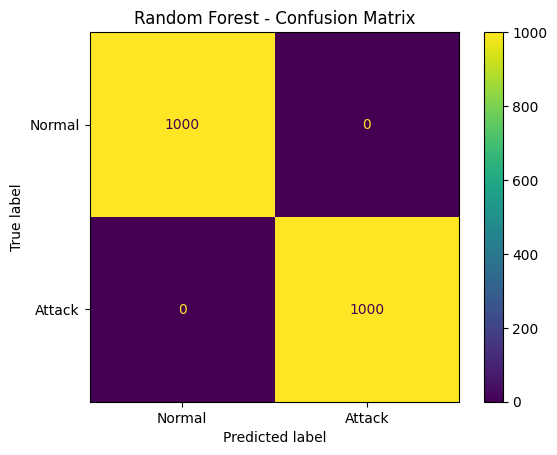

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import time

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_model.fit(X_train_processed, y_train)

training_time = time.time() - start_time

# Predict on unseen test data
y_pred_rf = rf_model.predict(X_test_processed)

# Evaluate the model
print("RANDOM FOREST RESULTS")
print("----------------------")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Training time: {training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Normal", "Attack"]
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

display.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [ ]:
# Check numerical feature correlations safely

from IPython.display import display as show_table

# Exclude constant columns because correlation is undefined for them
varying_numeric_cols = [
    col for col in numeric_cols
    if df[col].nunique(dropna=False) > 1
]

correlations = (
    df[varying_numeric_cols]
    .corrwith(df["attack"])
    .abs()
    .dropna()
    .sort_values(ascending=False)
)

print("Number of numerical features checked:", len(varying_numeric_cols))
print("\nTop numerical feature correlations with attack:")

show_table(
    correlations.head(15).to_frame("Absolute correlation")
)

Number of numerical features checked: 19

Top numerical feature correlations with attack:


,Absolute correlation
state_number,1.000000
pkts,0.657279
dpkts,0.657149
spkts,0.657149
dbytes,0.560945
sbytes,0.560945
bytes,0.560943
sum,0.560943
dur,0.429099
dport,0.257716


In [ ]:
from sklearn.metrics import accuracy_score

y_train_pred = rf_model.predict(X_train_processed)
y_test_pred = rf_model.predict(X_test_processed)

print("Training accuracy:",
      accuracy_score(y_train, y_train_pred))

print("Testing accuracy:",
      accuracy_score(y_test, y_test_pred))

Training accuracy: 1.0
Testing accuracy: 1.0


In [ ]:
print("State values:")
print(df["state"].value_counts(dropna=False))

print("\nState number mapping:")
print(
    df[["state", "state_number", "attack", "category"]]
    .drop_duplicates()
    .sort_values(["state_number", "state"])
    .to_string(index=False)
)

print("\nCross-tabulation: state_number vs attack")
print(pd.crosstab(df["state_number"], df["attack"]))

State values:
state
ESTABLISHED    5000
ATTACK         5000
Name: count, dtype: int64

State number mapping:
      state  state_number  attack       category
ESTABLISHED             1       0         Benign
     ATTACK             2       1            DoS
     ATTACK             2       1           DDoS
     ATTACK             2       1 Reconnaissance
     ATTACK             2       1          Theft

Cross-tabulation: state_number vs attack
attack           0     1
state_number            
1             5000     0
2                0  5000


In [ ]:
# Remove features that directly reveal the target
columns_to_drop = [
    "attack", "category", "subcategory",
    "pkSeqID", "stime", "ltime", "saddr", "daddr", "seq",
    "state", "state_number"
]

X = df.drop(columns=columns_to_drop, errors="ignore")
y = df["attack"].astype(int)

# Split again
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify feature types
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

# Build and fit preprocessing using training data only
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Train a fresh Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Training accuracy:",
      accuracy_score(y_train, rf_model.predict(X_train_processed)))

print("Testing accuracy:",
      accuracy_score(y_test, rf_model.predict(X_test_processed)))

Training accuracy: 1.0
Testing accuracy: 0.9365


Updated Random Forest Results
-----------------------------
Accuracy: 0.9365

Classification Report:
              precision    recall  f1-score   support

      Normal       0.90      0.98      0.94      1000
      Attack       0.97      0.90      0.93      1000

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000



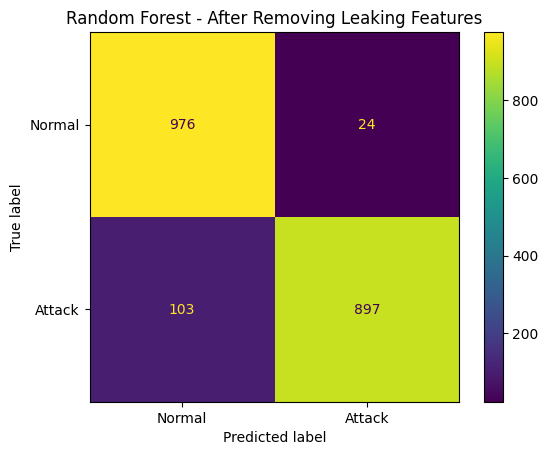

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)
import matplotlib.pyplot as plt

# Predict using the updated model
y_pred_rf = rf_model.predict(X_test_processed)

print("Updated Random Forest Results")
print("-----------------------------")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Normal", "Attack"]
))

cm = confusion_matrix(y_test, y_pred_rf)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

cm_display.plot()
plt.title("Random Forest - After Removing Leaking Features")
plt.show()

In [ ]:
# Install XGBoost if needed
%pip -q install xgboost

XGBOOST RESULTS
----------------
Accuracy: 0.9310
Training time: 0.76 seconds

Classification Report:
              precision    recall  f1-score   support

      Normal       0.91      0.96      0.93      1000
      Attack       0.96      0.90      0.93      1000

    accuracy                           0.93      2000
   macro avg       0.93      0.93      0.93      2000
weighted avg       0.93      0.93      0.93      2000



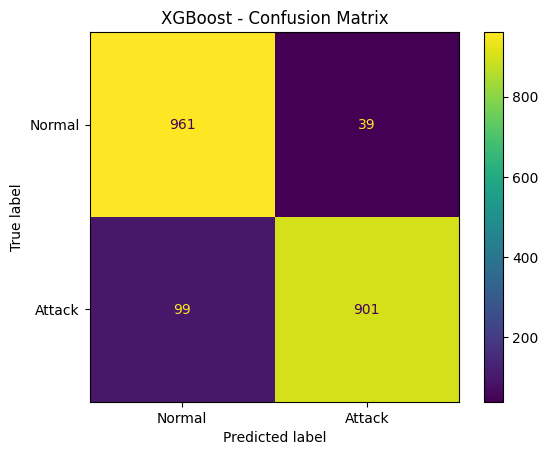

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import time

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

# Train
start_time = time.time()
xgb_model.fit(X_train_processed, y_train)
xgb_training_time = time.time() - start_time

# Predict
y_pred_xgb = xgb_model.predict(X_test_processed)

# Evaluate
print("XGBOOST RESULTS")
print("----------------")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"Training time: {xgb_training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["Normal", "Attack"]
))

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

cm_display_xgb = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Normal", "Attack"]
)

cm_display_xgb.plot()
plt.title("XGBoost - Confusion Matrix")
plt.show()

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8783 - loss: 0.2913 - val_accuracy: 0.9069 - val_loss: 0.2198
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9169 - loss: 0.1956 - val_accuracy: 0.9125 - val_loss: 0.1982
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9245 - loss: 0.1784 - val_accuracy: 0.9181 - val_loss: 0.1851
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9275 - loss: 0.1672 - val_accuracy: 0.9194 - val_loss: 0.1757
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9333 - loss: 0.1562 - val_accuracy: 0.9250 - val_loss: 0.1672
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9320 - loss: 0.1501 - val_accuracy: 0.9250 - val_loss: 0.1622
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9361 - loss: 0.1448 - val_accuracy: 0.9275 - val_loss: 0.1593
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9377 - loss: 0.1405 - val_accuracy: 0

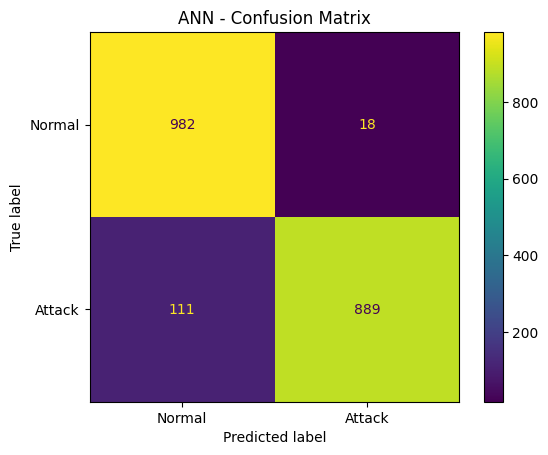

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import time

# Make results more reproducible
tf.keras.utils.set_random_seed(42)

# Build ANN
ann_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start_time = time.time()

history = ann_model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

ann_training_time = time.time() - start_time

# Evaluate on the untouched test split
ann_probabilities = ann_model.predict(
    X_test_processed,
    verbose=0
).ravel()

y_pred_ann = (ann_probabilities >= 0.5).astype(int)

print("\nANN RESULTS")
print("-----------")
print(f"Accuracy: {accuracy_score(y_test, y_pred_ann):.4f}")
print(f"Training time: {ann_training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_ann,
    target_names=["Normal", "Attack"]
))

cm_ann = confusion_matrix(y_test, y_pred_ann)

cm_display_ann = ConfusionMatrixDisplay(
    confusion_matrix=cm_ann,
    display_labels=["Normal", "Attack"]
)

cm_display_ann.plot()
plt.title("ANN - Confusion Matrix")
plt.show()

In [ ]:
from IPython.display import display as show_table

show_table(
    results.sort_values(
        by="Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)

NameError: name 'results' is not defined

In [ ]:
import pandas as pd
from IPython.display import display as show_table

results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost", "ANN"],
    "Accuracy (%)": [93.65, 93.10, 93.55],
    "Attack Precision (%)": [97, 96, 98],
    "Attack Recall (%)": [90, 90, 89],
    "Attack F1-score (%)": [93, 93, 93],
    "Training Time (seconds)": [1.04, 2.83, 25.40]
})

results = results.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

show_table(results)

,Model,Accuracy (%),Attack Precision (%),Attack Recall (%),Attack F1-score (%),Training Time (seconds)
0,Random Forest,93.65,97,90,93,1.04
1,ANN,93.55,98,89,93,25.40
2,XGBoost,93.10,96,90,93,2.83


In [ ]:
import pandas as pd
from IPython.display import display as show_table

results = pd.DataFrame([
    ["Random Forest", 93.65, 97, 90, 93, 1.04],
    ["ANN",           93.55, 98, 89, 93, 25.40],
    ["XGBoost",       93.10, 96, 90, 93, 2.83]
], columns=[
    "Model",
    "Accuracy (%)",
    "Attack Precision (%)",
    "Attack Recall (%)",
    "Attack F1-score (%)",
    "Training Time (seconds)"
])

show_table(results)

,Model,Accuracy (%),Attack Precision (%),Attack Recall (%),Attack F1-score (%),Training Time (seconds)
0,Random Forest,93.65,97,90,93,1.04
1,ANN,93.55,98,89,93,25.40
2,XGBoost,93.10,96,90,93,2.83


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Random Forest", "ANN", "XGBoost"],
    "Accuracy (%)": [93.65, 93.55, 93.10],
    "Attack Precision (%)": [97, 98, 96],
    "Attack Recall (%)": [90, 89, 90],
    "Attack F1-score (%)": [93, 93, 93],
    "Training Time (seconds)": [1.04, 25.40, 2.83]
})

print(results.to_string(index=False))

        Model  Accuracy (%)  Attack Precision (%)  Attack Recall (%)  Attack F1-score (%)  Training Time (seconds)
Random Forest         93.65                    97                 90                   93                     1.04
          ANN         93.55                    98                 89                   93                    25.40
      XGBoost         93.10                    96                 90                   93                     2.83


In [ ]:

import pandas as pd

# Combine training features and target
train_data = X_train.copy()
train_data["attack"] = y_train

# Select numerical features
numeric_features = train_data.select_dtypes(
    include=["number"]
).columns.drop("attack")

# Remove constant features
numeric_features = [
    col for col in numeric_features
    if train_data[col].nunique() > 1
]

# Calculate absolute PCC scores
pcc_scores = (
    train_data[numeric_features]
    .corrwith(train_data["attack"])
    .abs()
    .dropna()
    .sort_values(ascending=False)
)

# Display the top 15 features
print("Top 15 features based on absolute PCC:")
print(pcc_scores.head(15).to_string())


Top 15 features based on absolute PCC:
pkts            0.653122
spkts           0.653070
dpkts           0.653070
sbytes          0.561531
dbytes          0.561531
bytes           0.561530
sum             0.561530
dur             0.426689
dport           0.253006
proto_number    0.248352
rate            0.236153
drate           0.236153
srate           0.236153
mean            0.127212
min             0.019236


In [ ]:

# Select the top 15 numerical features from PCC
top_features = pcc_scores.head(15).index.tolist()

print("Selected PCC features:")
for i, feature in enumerate(top_features, start=1):
    print(f"{i}. {feature}")

print("\nNumber of selected features:", len(top_features))


Selected PCC features:
1. pkts
2. spkts
3. dpkts
4. sbytes
5. dbytes
6. bytes
7. sum
8. dur
9. dport
10. proto_number
11. rate
12. drate
13. srate
14. mean
15. min

Number of selected features: 15


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Select the 15 PCC features
X_pcc = X[top_features].copy()

# Reuse the existing train/test row split
X_train_pcc = X_pcc.loc[X_train.index]
X_test_pcc = X_pcc.loc[X_test.index]

# Identify numerical and categorical columns
numeric_cols_pcc = X_train_pcc.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols_pcc = X_train_pcc.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Create preprocessing pipeline
preprocessor_pcc = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols_pcc),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols_pcc)
    ]
)

# Fit only on training data
X_train_pcc_processed = preprocessor_pcc.fit_transform(X_train_pcc)
X_test_pcc_processed = preprocessor_pcc.transform(X_test_pcc)

print("Selected features:", len(top_features))
print("Processed training shape:", X_train_pcc_processed.shape)
print("Processed testing shape:", X_test_pcc_processed.shape)


Selected features: 15
Processed training shape: (8000, 15)
Processed testing shape: (2000, 15)


In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from xgboost import XGBClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Convert processed data to arrays
Xtr = np.asarray(X_train_pcc_processed, dtype=np.float32)
Xte = np.asarray(X_test_pcc_processed, dtype=np.float32)

ytr = np.asarray(y_train).ravel().astype(int)
yte = np.asarray(y_test).ravel().astype(int)

pcc_results = []

# 1. Random Forest
rf_pcc = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start = time.time()
rf_pcc.fit(Xtr, ytr)
rf_time = time.time() - start

rf_pred = rf_pcc.predict(Xte)

pcc_results.append({
    "Model": "Random Forest",
    "Accuracy (%)": accuracy_score(yte, rf_pred) * 100,
    "Attack Precision (%)": precision_score(yte, rf_pred, pos_label=1) * 100,
    "Attack Recall (%)": recall_score(yte, rf_pred, pos_label=1) * 100,
    "Attack F1-score (%)": f1_score(yte, rf_pred, pos_label=1) * 100,
    "Training Time (seconds)": rf_time
})

# 2. XGBoost
xgb_pcc = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

start = time.time()
xgb_pcc.fit(Xtr, ytr)
xgb_time = time.time() - start

xgb_pred = xgb_pcc.predict(Xte)

pcc_results.append({
    "Model": "XGBoost",
    "Accuracy (%)": accuracy_score(yte, xgb_pred) * 100,
    "Attack Precision (%)": precision_score(yte, xgb_pred, pos_label=1) * 100,
    "Attack Recall (%)": recall_score(yte, xgb_pred, pos_label=1) * 100,
    "Attack F1-score (%)": f1_score(yte, xgb_pred, pos_label=1) * 100,
    "Training Time (seconds)": xgb_time
})

# 3. ANN
ann_pcc = Sequential([
    Input(shape=(Xtr.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

ann_pcc.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start = time.time()
ann_pcc.fit(
    Xtr,
    ytr,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)
ann_time = time.time() - start

ann_prob = ann_pcc.predict(Xte, verbose=0).ravel()
ann_pred = (ann_prob >= 0.5).astype(int)

pcc_results.append({
    "Model": "ANN",
    "Accuracy (%)": accuracy_score(yte, ann_pred) * 100,
    "Attack Precision (%)": precision_score(yte, ann_pred, pos_label=1) * 100,
    "Attack Recall (%)": recall_score(yte, ann_pred, pos_label=1) * 100,
    "Attack F1-score (%)": f1_score(yte, ann_pred, pos_label=1) * 100,
    "Training Time (seconds)": ann_time
})

# Display PCC model comparison
pcc_results_df = pd.DataFrame(pcc_results)

print("PCC Feature Selection — Model Comparison")
print(
    pcc_results_df.sort_values(
        "Accuracy (%)", ascending=False
    ).round(2).to_string(index=False)
)


PCC Feature Selection — Model Comparison
        Model  Accuracy (%)  Attack Precision (%)  Attack Recall (%)  Attack F1-score (%)  Training Time (seconds)
      XGBoost         92.85                 95.63               89.8                92.63                     0.34
          ANN         92.75                 98.52               86.8                92.29                    37.22
Random Forest         92.60                 96.20               88.7                92.30                     1.03


In [ ]:

import numpy as np

# Convert the original processed features to arrays
X_train_lstm_base = np.asarray(
    X_train_processed, dtype=np.float32
)
X_test_lstm_base = np.asarray(
    X_test_processed, dtype=np.float32
)

y_train_lstm_base = np.asarray(y_train).ravel().astype(int)
y_test_lstm_base = np.asarray(y_test).ravel().astype(int)

# Check dimensions before creating sequences
print("Training features:", X_train_lstm_base.shape)
print("Testing features:", X_test_lstm_base.shape)
print("Training labels:", y_train_lstm_base.shape)
print("Testing labels:", y_test_lstm_base.shape)


Training features: (8000, 47)
Testing features: (2000, 47)
Training labels: (8000,)
Testing labels: (2000,)


In [ ]:

# Inspect the original dataset order
print("Dataset shape:", df.shape)

if "pkSeqID" in df.columns:
    print("\nFirst 10 packet sequence IDs:")
    print(df["pkSeqID"].head(10).to_list())

    print("\nLast 10 packet sequence IDs:")
    print(df["pkSeqID"].tail(10).to_list())

if "stime" in df.columns:
    print("\nFirst 10 start times:")
    print(df["stime"].head(10).to_list())

    print("\nAre start times already sorted?")
    print(df["stime"].is_monotonic_increasing)


Dataset shape: (10000, 46)

First 10 packet sequence IDs:
[2309, 22405, 23398, 25059, 2665, 8512, 5149, 7791, 11312, 19044]

Last 10 packet sequence IDs:
[34991, 34992, 34993, 34994, 34995, 34996, 34997, 34998, 34999, 35000]

First 10 start times:
['07-06-2025 10:36', '07-06-2025 10:36', '07-06-2025 10:36', '07-06-2025 10:36', '07-06-2025 10:36', '07-06-2025 10:36', '07-06-2025 10:36', '07-06-2025 10:36', '07-06-2025 10:36', '07-06-2025 10:36']

Are start times already sorted?
True


In [ ]:

import pandas as pd

# Parse timestamps using the format shown in your dataset
df["parsed_time"] = pd.to_datetime(
    df["stime"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

print("Valid timestamps:", df["parsed_time"].notna().sum())
print("Unique timestamps:", df["parsed_time"].nunique())

print(
    "Chronologically sorted:",
    df["parsed_time"].is_monotonic_increasing
)

print(
    "Packet IDs sorted:",
    df["pkSeqID"].is_monotonic_increasing
)

print("\nFirst 10 records after sorting by time and packet ID:")
print(
    df.sort_values(["parsed_time", "pkSeqID"])[
        ["parsed_time", "pkSeqID", "attack"]
    ].head(10).to_string(index=False)
)


Valid timestamps: 10000
Unique timestamps: 1
Chronologically sorted: True
Packet IDs sorted: False

First 10 records after sorting by time and packet ID:
        parsed_time  pkSeqID  attack
2025-06-07 10:36:00        7       0
2025-06-07 10:36:00       18       0
2025-06-07 10:36:00       35       0
2025-06-07 10:36:00       36       0
2025-06-07 10:36:00       44       0
2025-06-07 10:36:00       47       0
2025-06-07 10:36:00       53       0
2025-06-07 10:36:00       76       0
2025-06-07 10:36:00       92       0
2025-06-07 10:36:00       93       0


In [ ]:

print("Unique packet IDs:", df["pkSeqID"].nunique())
print("Duplicate packet IDs:", df["pkSeqID"].duplicated().sum())
print("Minimum packet ID:", df["pkSeqID"].min())
print("Maximum packet ID:", df["pkSeqID"].max())

expected_ids = set(range(
    int(df["pkSeqID"].min()),
    int(df["pkSeqID"].max()) + 1
))
actual_ids = set(df["pkSeqID"].dropna().astype(int))

print("Missing IDs in range:", len(expected_ids - actual_ids))


Unique packet IDs: 10000
Duplicate packet IDs: 0
Minimum packet ID: 7
Maximum packet ID: 35000
Missing IDs in range: 24994


In [ ]:

# Check whether records share source/destination information
flow_columns = ["saddr", "daddr", "sport", "dport", "proto"]

print("Unique values per flow-related column:\n")

for col in flow_columns:
    print(f"{col}: {df[col].nunique()} unique values")

print("\nExample flow records:")
print(
    df[flow_columns + ["pkSeqID", "attack"]]
    .head(10)
    .to_string(index=False)
)


Unique values per flow-related column:

saddr: 7 unique values
daddr: 354 unique values
sport: 9257 unique values
dport: 11 unique values
proto: 11 unique values

Example flow records:
         saddr           daddr  sport  dport proto  pkSeqID  attack
192.168.100.11 192.168.100.127  29246   1900  SSDP     2309       0
192.168.100.15 192.168.100.234  42620     80  HTTP    22405       0
192.168.100.15 192.168.100.217  38854     53   DNS    23398       0
192.168.100.16 192.168.100.220  29319     53   DNS    25059       0
192.168.100.11 192.168.100.174  52577     53   DNS     2665       0
192.168.100.12  192.168.100.31  64527     80  HTTP     8512       0
192.168.100.12 192.168.100.125  31302     80  HTTP     5149       0
192.168.100.12 192.168.100.152   4598     80  HTTP     7791       0
192.168.100.13  192.168.100.78  64501     53   DNS    11312       0
192.168.100.14 192.168.100.104   5875     80  HTTP    19044       0


In [ ]:

import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Random Forest", "ANN", "XGBoost"],
    "Baseline Accuracy (%)": [93.65, 93.55, 93.10],
    "PCC Accuracy (%)": [92.60, 92.75, 92.85],
    "Baseline Attack Recall (%)": [90.0, 89.0, 90.0],
    "PCC Attack Recall (%)": [88.7, 86.8, 89.8]
})

comparison["Accuracy Change"] = (
    comparison["PCC Accuracy (%)"]
    - comparison["Baseline Accuracy (%)"]
)

print(comparison.round(2).to_string(index=False))


        Model  Baseline Accuracy (%)  PCC Accuracy (%)  Baseline Attack Recall (%)  PCC Attack Recall (%)  Accuracy Change
Random Forest                  93.65             92.60                        90.0                   88.7            -1.05
          ANN                  93.55             92.75                        89.0                   86.8            -0.80
      XGBoost                  93.10             92.85                        90.0                   89.8            -0.25


In [ ]:

import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create a complete pipeline: preprocessing + Random Forest
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train using the original baseline training data
final_pipeline.fit(X_train, y_train)

# Save the complete pipeline
joblib.dump(
    final_pipeline,
    "iot_intrusion_rf_pipeline.joblib"
)

print("Random Forest pipeline trained and saved successfully.")


Random Forest pipeline trained and saved successfully.


In [ ]:

from google.colab import files

files.download("iot_intrusion_rf_pipeline.joblib")


In [ ]:

# Check the distribution of normal and attack records by source
source_attack_counts = pd.crosstab(
    df["saddr"],
    df["attack"],
    margins=True
)

print("Attack distribution by source device:")
print(source_attack_counts)

print("\nNumber of unique source devices:", df["saddr"].nunique())


Attack distribution by source device:
attack              0     1    All
saddr                             
192.168.100.11    810     0    810
192.168.100.12    863     0    863
192.168.100.13    877     0    877
192.168.100.14    800     0    800
192.168.100.147     0  5000   5000
192.168.100.15    855     0    855
192.168.100.16    795     0    795
All              5000  5000  10000

Number of unique source devices: 7


In [ ]:

# Compare normal and attack traffic using selected numeric features

features_to_check = [
    "pkts", "bytes", "dur", "rate",
    "srate", "drate", "spkts", "dpkts",
    "sbytes", "dbytes"
]

print("Mean feature values for normal vs attack traffic:\n")
print(df.groupby("attack")[features_to_check].mean().T.round(3))


Mean feature values for normal vs attack traffic:

attack         0          1
pkts      27.323     60.263
bytes   2655.842   5461.664
dur        1.287      0.742
rate    3612.334  18611.136
srate   1805.819   9304.680
drate   1805.819   9304.680
spkts     13.413     29.886
dpkts     13.413     29.886
sbytes  1327.662   2730.579
dbytes  1327.662   2730.579


In [ ]:

# Create features without source and destination IP addresses

X_no_ip = df.drop(
    columns=[
        "attack", "category", "subcategory",
        "pkSeqID", "stime", "ltime",
        "saddr", "daddr", "seq",
        "state", "state_number"
    ],
    errors="ignore"
)

y_no_ip = df["attack"].astype(int)

print("Dataset shape without IP addresses:", X_no_ip.shape)
print("\nRemaining categorical columns:")
print(X_no_ip.select_dtypes(include=["object"]).columns.tolist())

print("\nTarget distribution:")
print(y_no_ip.value_counts())


Dataset shape without IP addresses: (10000, 36)

Remaining categorical columns:
['flgs', 'proto']

Target distribution:
attack
0    5000
1    5000
Name: count, dtype: int64


In [ ]:

import time
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Split the dataset
X_train_no_ip, X_test_no_ip, y_train_no_ip, y_test_no_ip = train_test_split(
    X_no_ip,
    y_no_ip,
    test_size=0.2,
    random_state=42,
    stratify=y_no_ip
)

# 2. Identify numeric and categorical features
numeric_features = X_no_ip.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_no_ip.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# 3. Preprocess the features
preprocessor_no_ip = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# 4. Create the Random Forest pipeline
rf_no_ip = Pipeline([
    ("preprocessor", preprocessor_no_ip),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# 5. Train and evaluate
start_time = time.time()
rf_no_ip.fit(X_train_no_ip, y_train_no_ip)
training_time_no_ip = time.time() - start_time

y_pred_no_ip = rf_no_ip.predict(X_test_no_ip)

print("Random Forest — Without IP Addresses")
print("-------------------------------------")
print(f"Accuracy: {accuracy_score(y_test_no_ip, y_pred_no_ip) * 100:.2f}%")
print(f"Training time: {training_time_no_ip:.2f} seconds")

print("\nClassification Report:")
print(classification_report(y_test_no_ip, y_pred_no_ip))

print("Confusion Matrix:")
print(confusion_matrix(y_test_no_ip, y_pred_no_ip))


Random Forest — Without IP Addresses
-------------------------------------
Accuracy: 93.65%
Training time: 1.01 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.98      0.94      1000
           1       0.97      0.90      0.93      1000

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000

Confusion Matrix:
[[976  24]
 [103 897]]


In [ ]:

# Check whether pkSeqID can support meaningful ordering

df_ordered = df.sort_values("pkSeqID").reset_index(drop=True)

id_gaps = df_ordered["pkSeqID"].diff().dropna()

print("Number of records:", len(df_ordered))
print("Unique timestamps:", df["stime"].nunique())
print("Unique packet IDs:", df["pkSeqID"].nunique())

print("\nPacket ID gap statistics:")
print(id_gaps.describe())

print("\nNumber of adjacent records with a gap greater than 1:",
      (id_gaps > 1).sum())

print("\nAttack-label changes between adjacent sorted records:",
      (df_ordered["attack"].ne(
          df_ordered["attack"].shift()
      ).iloc[1:]).sum())

print("\nFirst 15 ordered records:")
print(df_ordered[["pkSeqID", "attack", "category"]].head(15))


Number of records: 10000
Unique timestamps: 1
Unique packet IDs: 10000

Packet ID gap statistics:
count    9999.000000
mean        3.499650
std         4.599087
min         1.000000
25%         1.000000
50%         1.000000
75%         4.000000
max        52.000000
Name: pkSeqID, dtype: float64

Number of adjacent records with a gap greater than 1: 4196

Attack-label changes between adjacent sorted records: 1

First 15 ordered records:
    pkSeqID  attack category
0         7       0   Benign
1        18       0   Benign
2        35       0   Benign
3        36       0   Benign
4        44       0   Benign
5        47       0   Benign
6        53       0   Benign
7        76       0   Benign
8        92       0   Benign
9        93       0   Benign
10       97       0   Benign
11      100       0   Benign
12      122       0   Benign
13      128       0   Benign
14      145       0   Benign


In [ ]:
import os

print("Files available in the current Colab folder:\n")

for file in os.listdir("/content"):
    print(file)

In [ ]:

from IPython.display import display as show_output

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
show_output(df.head())

print("\nTimestamp information:")
if "stime" in df.columns:
    print("Unique timestamps:", df["stime"].nunique())
    print(df["stime"].head().to_string(index=False))

print("\nPacket ID information:")
if "pkSeqID" in df.columns:
    print("Unique packet IDs:", df["pkSeqID"].nunique())
    print("Minimum packet ID:", df["pkSeqID"].min())
    print("Maximum packet ID:", df["pkSeqID"].max())


Dataset shape: (10000, 47)

First 5 rows:


,pkSeqID,stime,flgs,flgs_number,proto,proto_number,saddr,sport,daddr,dport,...,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack,category,subcategory,parsed_time
0,2309,07-06-2025 10:36,U,1,SSDP,17,192.168.100.11,29246,192.168.100.127,1900,...,1,1,1,1,1,1,0,Benign,normal,2025-06-07 10:36:00
1,22405,07-06-2025 10:36,PA,1,HTTP,6,192.168.100.15,42620,192.168.100.234,80,...,1,1,1,1,1,1,0,Benign,normal,2025-06-07 10:36:00
2,23398,07-06-2025 10:36,U,1,DNS,17,192.168.100.15,38854,192.168.100.217,53,...,1,1,1,1,1,1,0,Benign,normal,2025-06-07 10:36:00
3,25059,07-06-2025 10:36,U,1,DNS,17,192.168.100.16,29319,192.168.100.220,53,...,1,1,1,1,1,1,0,Benign,normal,2025-06-07 10:36:00
4,2665,07-06-2025 10:36,U,1,DNS,17,192.168.100.11,52577,192.168.100.174,53,...,1,1,1,1,1,1,0,Benign,normal,2025-06-07 10:36:00



Timestamp information:
Unique timestamps: 1
07-06-2025 10:36
07-06-2025 10:36
07-06-2025 10:36
07-06-2025 10:36
07-06-2025 10:36

Packet ID information:
Unique packet IDs: 10000
Minimum packet ID: 7
Maximum packet ID: 35000


In [ ]:

# Sort records by packet ID
df_sorted = df.sort_values("pkSeqID").reset_index(drop=True)

# Check gaps between consecutive packet IDs
id_gaps = df_sorted["pkSeqID"].diff().dropna()

print("Packet ID gap statistics:")
print(id_gaps.describe())

print("\nNumber of gaps greater than 1:", (id_gaps > 1).sum())

print("\nAttack labels in the first 20 sorted records:")
print(df_sorted[["pkSeqID", "attack", "category"]].head(20).to_string(index=False))

print("\nAttack label changes after sorting:")
print("Number of label changes:",
      (df_sorted["attack"].diff().dropna() != 0).sum())

print("\nAttack distribution after sorting:")
print(df_sorted["attack"].value_counts().sort_index())


Packet ID gap statistics:
count    9999.000000
mean        3.499650
std         4.599087
min         1.000000
25%         1.000000
50%         1.000000
75%         4.000000
max        52.000000
Name: pkSeqID, dtype: float64

Number of gaps greater than 1: 4196

Attack labels in the first 20 sorted records:
 pkSeqID  attack category
       7       0   Benign
      18       0   Benign
      35       0   Benign
      36       0   Benign
      44       0   Benign
      47       0   Benign
      53       0   Benign
      76       0   Benign
      92       0   Benign
      93       0   Benign
      97       0   Benign
     100       0   Benign
     122       0   Benign
     128       0   Benign
     145       0   Benign
     148       0   Benign
     151       0   Benign
     168       0   Benign
     174       0   Benign
     189       0   Benign

Attack label changes after sorting:
Number of label changes: 1

Attack distribution after sorting:
attack
0    5000
1    5000
Name: count, dtype:

In [ ]:

# Find where the attack label changes
label_changes = df_sorted["attack"].ne(df_sorted["attack"].shift())

print("Rows around the label transition:")
change_positions = label_changes[label_changes].index.tolist()

for pos in change_positions:
    start = max(0, pos - 5)
    end = min(len(df_sorted), pos + 5)

    print(f"\nRows {start} to {end - 1}:")
    print(
        df_sorted.loc[start:end - 1, ["pkSeqID", "attack", "category"]]
        .to_string(index=False)
    )


Rows around the label transition:

Rows 0 to 4:
 pkSeqID  attack category
       7       0   Benign
      18       0   Benign
      35       0   Benign
      36       0   Benign
      44       0   Benign

Rows 4995 to 5004:
 pkSeqID  attack category
   29986       0   Benign
   29989       0   Benign
   29990       0   Benign
   29996       0   Benign
   30000       0   Benign
   30001       1      DoS
   30002       1      DoS
   30003       1      DoS
   30004       1     DDoS
   30005       1     DDoS


In [ ]:

# Check available columns that might help identify sequences
possible_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in [
        "time", "seq", "flow", "session", "device", "source", "dest"
    ])
]

print("Potential sequence-related columns:")
print(possible_columns)

print("\nTimestamp columns:")
for col in ["stime", "ltime"]:
    if col in df.columns:
        print(f"{col}: {df[col].nunique()} unique values")

print("\nSource IP distribution by attack label:")
print(pd.crosstab(df["saddr"], df["attack"]))


Potential sequence-related columns:
['pkSeqID', 'stime', 'ltime', 'seq', 'Pkts_P_State_P_Protocol_P_DestIP', 'parsed_time']

Timestamp columns:
stime: 1 unique values
ltime: 1 unique values

Source IP distribution by attack label:
attack             0     1
saddr                     
192.168.100.11   810     0
192.168.100.12   863     0
192.168.100.13   877     0
192.168.100.14   800     0
192.168.100.147    0  5000
192.168.100.15   855     0
192.168.100.16   795     0


In [ ]:

# Check whether attack labels are grouped in the original CSV order
label_changes_original = (
    df["attack"].ne(df["attack"].shift()).sum() - 1
)

print("Label changes in original row order:", label_changes_original)

print("\nFirst 10 original labels:")
print(df[["pkSeqID", "attack", "category"]].head(10).to_string(index=False))

print("\nLast 10 original labels:")
print(df[["pkSeqID", "attack", "category"]].tail(10).to_string(index=False))

print("\nSource IPs and number of labels associated with each:")
print(
    df.groupby("saddr")["attack"]
      .nunique()
      .sort_values()
      .to_string()
)



Label changes in original row order: 1

First 10 original labels:
 pkSeqID  attack category
    2309       0   Benign
   22405       0   Benign
   23398       0   Benign
   25059       0   Benign
    2665       0   Benign
    8512       0   Benign
    5149       0   Benign
    7791       0   Benign
   11312       0   Benign
   19044       0   Benign

Last 10 original labels:
 pkSeqID  attack       category
   34991       1 Reconnaissance
   34992       1          Theft
   34993       1            DoS
   34994       1            DoS
   34995       1            DoS
   34996       1           DDoS
   34997       1           DDoS
   34998       1 Reconnaissance
   34999       1 Reconnaissance
   35000       1          Theft

Source IPs and number of labels associated with each:
saddr
192.168.100.11     1
192.168.100.12     1
192.168.100.13     1
192.168.100.14     1
192.168.100.147    1
192.168.100.15     1
192.168.100.16     1


In [ ]:

import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d != ".config" and d != "sample_data"]

    for file in files:
        if "readme" in file.lower() or "dictionary" in file.lower():
            print(os.path.join(root, file))


In [ ]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, classification_report
import time

# Make results more reproducible
np.random.seed(42)
tf.random.set_seed(42)

# Convert processed features to NumPy arrays if necessary
X_train_lstm = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else np.asarray(X_train_processed)
)

X_test_lstm = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else np.asarray(X_test_processed)
)

y_train_lstm = np.asarray(y_train_lstm_base).reshape(-1)
y_test_lstm = np.asarray(y_test_lstm_base).reshape(-1)

# Reshape each record into a feature sequence
X_train_lstm = X_train_lstm.reshape(
    X_train_lstm.shape[0], X_train_lstm.shape[1], 1
)

X_test_lstm = X_test_lstm.reshape(
    X_test_lstm.shape[0], X_test_lstm.shape[1], 1
)

print("LSTM training shape:", X_train_lstm.shape)
print("LSTM testing shape:", X_test_lstm.shape)

# Build the LSTM model
lstm_model = Sequential([
    Input(shape=(X_train_lstm.shape[1], 1)),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train
start_time = time.time()

history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

lstm_training_time = time.time() - start_time

# Evaluate on the held-out test set
y_prob_lstm = lstm_model.predict(X_test_lstm, verbose=0).ravel()
y_pred_lstm = (y_prob_lstm >= 0.5).astype(int)

lstm_accuracy = accuracy_score(y_test_lstm, y_pred_lstm)

print("\nLSTM Accuracy:", round(lstm_accuracy * 100, 2), "%")
print("Training time:", round(lstm_training_time, 2), "seconds")
print("\nClassification Report:")
print(classification_report(y_test_lstm, y_pred_lstm))


LSTM training shape: (8000, 47, 1)
LSTM testing shape: (2000, 47, 1)
Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7570 - loss: 0.4861 - val_accuracy: 0.8087 - val_loss: 0.4246
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8395 - loss: 0.3701 - val_accuracy: 0.8150 - val_loss: 0.4214
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8475 - loss: 0.3559 - val_accuracy: 0.8238 - val_loss: 0.4159
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8531 - loss: 0.3406 - val_accuracy: 0.8306 - val_loss: 0.3885
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8573 - loss: 0.3205 - val_accuracy: 0.8219 - val_loss: 0.3797
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8592 - loss: 0.3125 - val_accuracy: 0.8338 - val_loss: 0.3479
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8655 - loss: 0.3005 - val_accuracy: 0.8456 - val_loss: 0.3304
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━

In [ ]:

import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy (%)": 93.65,
        "Attack Precision (%)": 97.00,
        "Attack Recall (%)": 90.00,
        "Attack F1 (%)": 93.00,
        "Training Time (s)": 1.04
    },
    {
        "Model": "XGBoost",
        "Accuracy (%)": 93.10,
        "Attack Precision (%)": 96.00,
        "Attack Recall (%)": 90.00,
        "Attack F1 (%)": 93.00,
        "Training Time (s)": 2.83
    },
    {
        "Model": "ANN",
        "Accuracy (%)": 93.55,
        "Attack Precision (%)": 98.00,
        "Attack Recall (%)": 89.00,
        "Attack F1 (%)": 93.00,
        "Training Time (s)": 25.40
    },
    {
        "Model": "LSTM",
        "Accuracy (%)": 90.30,
        "Attack Precision (%)": 95.00,
        "Attack Recall (%)": 85.00,
        "Attack F1 (%)": 90.00,
        "Training Time (s)": 52.63
    }
])

print(results.to_string(index=False))


        Model  Accuracy (%)  Attack Precision (%)  Attack Recall (%)  Attack F1 (%)  Training Time (s)
Random Forest         93.65                  97.0               90.0           93.0               1.04
      XGBoost         93.10                  96.0               90.0           93.0               2.83
          ANN         93.55                  98.0               89.0           93.0              25.40
         LSTM         90.30                  95.0               85.0           90.0              52.63


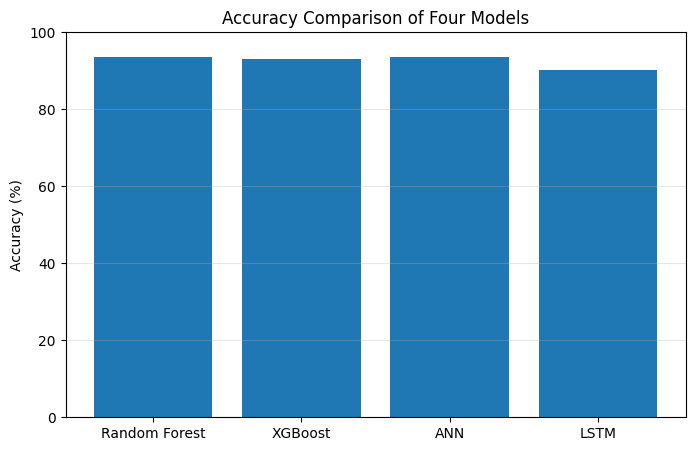

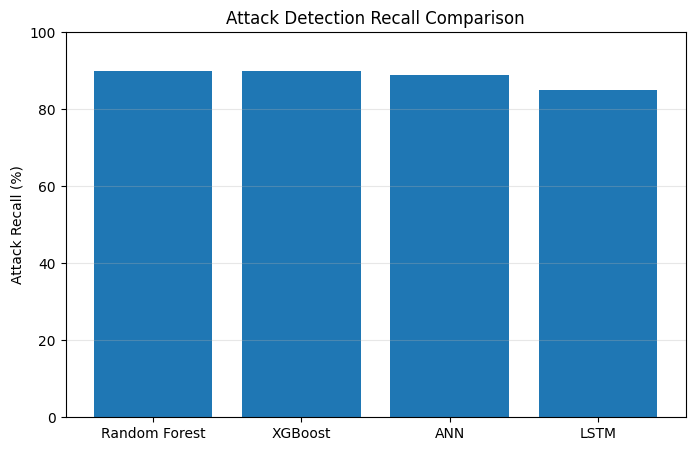

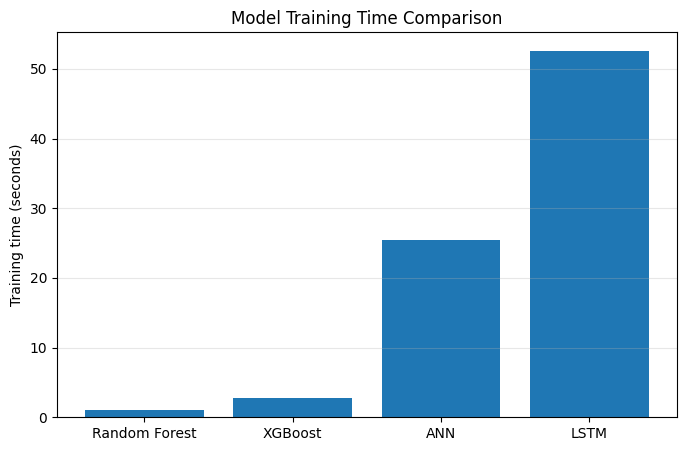

In [ ]:

import matplotlib.pyplot as plt

# 1. Accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison of Four Models")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.show()

# 2. Attack recall comparison
plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["Attack Recall (%)"])
plt.ylabel("Attack Recall (%)")
plt.title("Attack Detection Recall Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.show()

# 3. Training time comparison
plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["Training Time (s)"])
plt.ylabel("Training time (seconds)")
plt.title("Model Training Time Comparison")
plt.grid(axis="y", alpha=0.3)
plt.show()



In [ ]:

import joblib

model_path = "/content/iot_intrusion_rf_pipeline.joblib"

saved_pipeline = joblib.load(model_path)

print("Saved object type:", type(saved_pipeline))
print("\nPipeline details:")
print(saved_pipeline)

if hasattr(saved_pipeline, "named_steps"):
    print("\nPipeline steps:")
    for step_name, step_object in saved_pipeline.named_steps.items():
        print(step_name, ":", type(step_object).__name__)


Saved object type: <class 'sklearn.pipeline.Pipeline'>

Pipeline details:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['flgs_number',
                                                   'proto_number', 'sport',
                                                   'dport', 'pkts', 'bytes',
                                                   'dur', 'mean', 'stddev',
                                                   'sum', 'min', 'max', 'spkts',
                                                   'dpkts', 'sbytes', 'dbytes',
                                                   'rate', 'srate', 'drate',
                                                   'TnBPSrcIP', 'TnBPDstIP',
                                                   'TnP_PSrcIP', 'TnP_PDstIP',
                                                   'TnP_PerProto',
                                                   'TnP_Pe

In [ ]:

# Check the exact columns expected by the saved pipeline
print("Number of input features:",
      len(saved_pipeline.feature_names_in_))

print("\nExpected input columns:")
print(list(saved_pipeline.feature_names_in_))

# Check for columns that must not be used as prediction inputs
forbidden_columns = [
    "attack", "category", "subcategory",
    "state", "state_number",
    "pkSeqID", "stime", "ltime",
    "saddr", "daddr", "seq"
]

used_forbidden = [
    col for col in forbidden_columns
    if col in saved_pipeline.feature_names_in_
]

print("\nPotential leakage columns found:",
      used_forbidden if used_forbidden else "None")


Number of input features: 35

Expected input columns:
['flgs', 'flgs_number', 'proto', 'proto_number', 'sport', 'dport', 'pkts', 'bytes', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP', 'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP', 'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP']

Potential leakage columns found: None


In [ ]:

from google.colab import files

files.download("/content/iot_intrusion_rf_pipeline.joblib")


In [ ]:
import sklearn
import numpy
import pandas

print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)


Random Forest

Classification Report:
              precision    recall  f1-score   support

      Benign     0.9051    0.9730    0.9378      1000
      Attack     0.9708    0.8980    0.9330      1000

    accuracy                         0.9355      2000
   macro avg     0.9380    0.9355    0.9354      2000
weighted avg     0.9380    0.9355    0.9354      2000



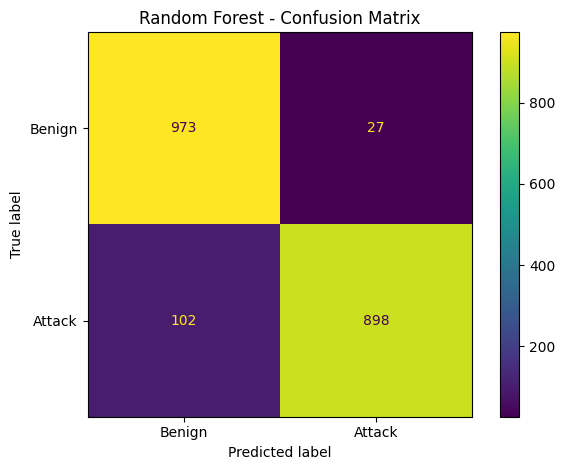


XGBoost

Classification Report:
              precision    recall  f1-score   support

      Benign     0.9066    0.9610    0.9330      1000
      Attack     0.9585    0.9010    0.9289      1000

    accuracy                         0.9310      2000
   macro avg     0.9326    0.9310    0.9309      2000
weighted avg     0.9326    0.9310    0.9309      2000



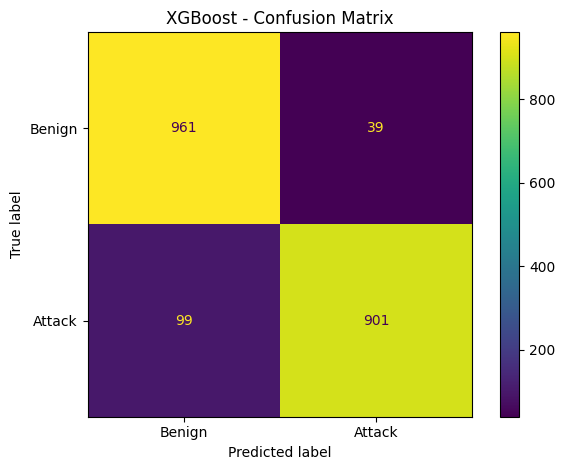


ANN

Classification Report:
              precision    recall  f1-score   support

      Benign     0.8984    0.9820    0.9384      1000
      Attack     0.9802    0.8890    0.9324      1000

    accuracy                         0.9355      2000
   macro avg     0.9393    0.9355    0.9354      2000
weighted avg     0.9393    0.9355    0.9354      2000



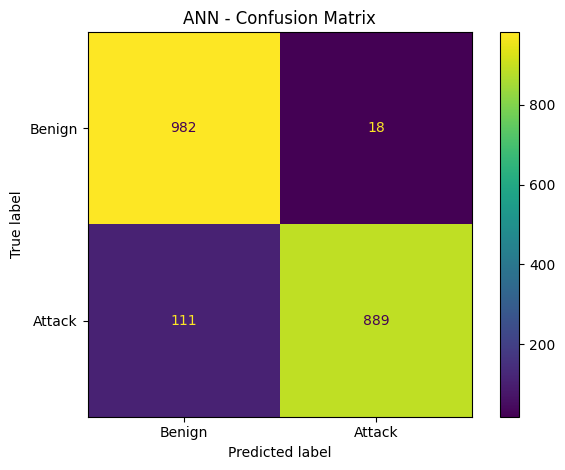


LSTM

Classification Report:
              precision    recall  f1-score   support

      Benign     0.8670    0.9520    0.9075      1000
      Attack     0.9468    0.8540    0.8980      1000

    accuracy                         0.9030      2000
   macro avg     0.9069    0.9030    0.9028      2000
weighted avg     0.9069    0.9030    0.9028      2000



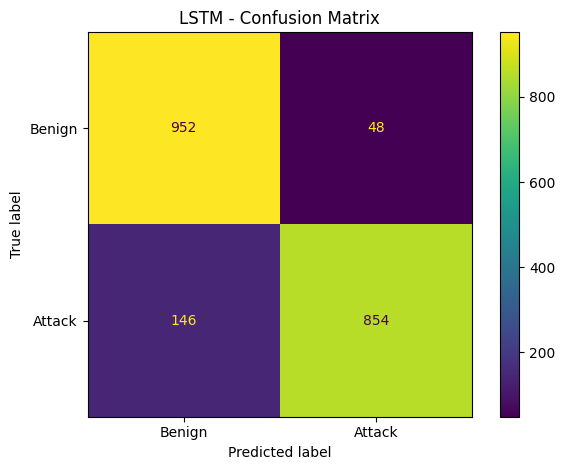


MODEL COMPARISON


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Update these names if your notebook uses different names.
# LSTM is reshaped into feature sequences, as in our experiment.
X_eval = np.asarray(X_test_processed)
y_true = np.asarray(y_test).astype(int)

X_lstm_eval = X_eval.reshape(
    X_eval.shape[0], X_eval.shape[1], 1
)

# Change the model variable names below to match your notebook.
models = {
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "ANN": ann_model,
    "LSTM": lstm_model
}

# Generate attack probabilities for ROC and PR curves.
def get_attack_scores(name, model):
    if name == "ANN":
        return model.predict(X_eval, verbose=0).ravel()

    elif name == "LSTM":
        return model.predict(X_lstm_eval, verbose=0).ravel()

    else:
        return model.predict_proba(X_eval)[:, 1]


results = []
scores = {}

for name, model in models.items():
    prob = get_attack_scores(name, model)
    pred = (prob >= 0.5).astype(int)

    scores[name] = prob

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    # 1. Classification report
    print("\nClassification Report:")
    print(classification_report(
        y_true, pred,
        labels=[0, 1],
        target_names=["Benign", "Attack"],
        digits=4,
        zero_division=0
    ))

    # 2. Confusion matrix
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Attack"]
    )
    disp.plot(values_format="d")
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # 3. Metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Attack Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Attack Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "Attack F1": f1_score(
            y_true, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC (Average Precision)": average_precision_score(
            y_true, prob
        )
    })

# 4. Comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.round(4))

# 5. ROC curve comparison
plt.figure(figsize=(8, 6))

for name, prob in scores.items():
    fpr, tpr, _ = roc_curve(y_true, prob)
    auc_value = roc_auc_score(y_true, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 6. Precision-Recall curve comparison
plt.figure(figsize=(8, 6))

for name, prob in scores.items():
    precision, recall, _ = precision_recall_curve(y_true, prob)
    ap = average_precision_score(y_true, prob)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 7. Accuracy, recall and F1 comparison
results_df.set_index("Model")[
    ["Accuracy", "Attack Recall", "Attack F1"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [ ]:
print(results_df.round(4).to_string(index=False))


        Model  Accuracy  Attack Precision  Attack Recall  Attack F1  ROC-AUC  PR-AUC (Average Precision)
Random Forest    0.9355            0.9708          0.898     0.9330   0.9871                      0.9881
      XGBoost    0.9310            0.9585          0.901     0.9289   0.9874                      0.9886
          ANN    0.9355            0.9802          0.889     0.9324   0.9862                      0.9878
         LSTM    0.9030            0.9468          0.854     0.8980   0.9665                      0.9722


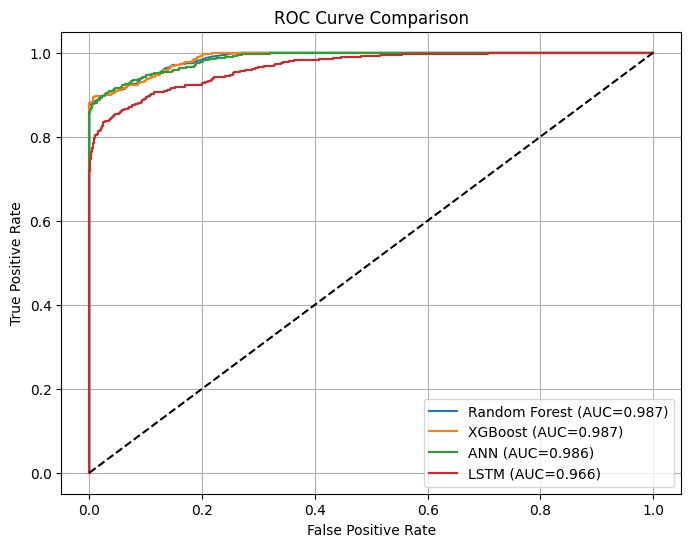

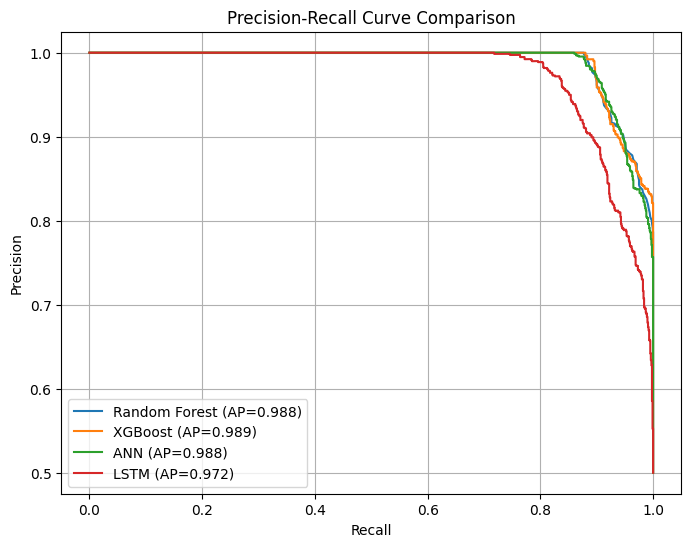

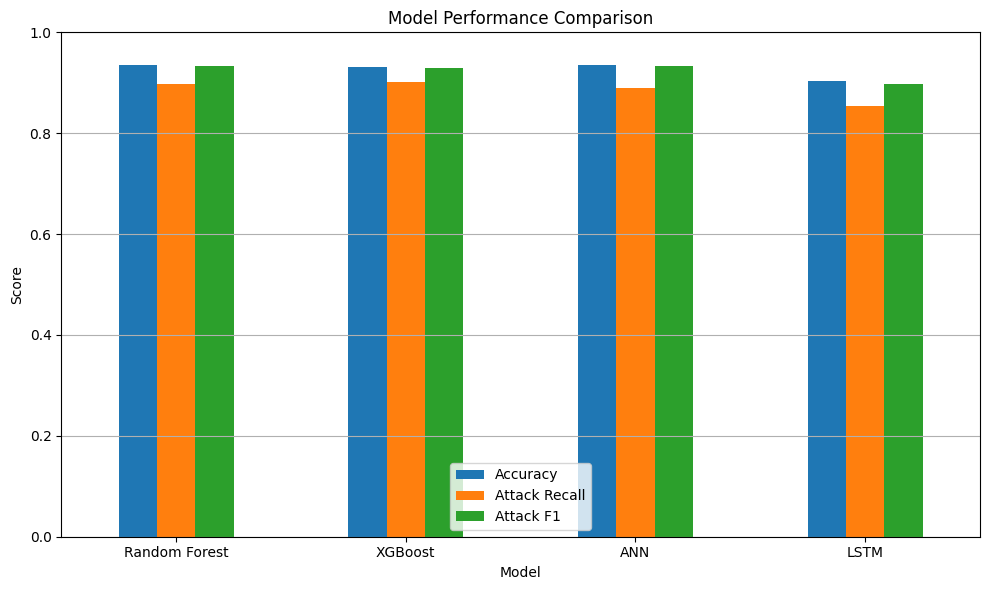

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# ROC curve comparison
plt.figure(figsize=(8, 6))

for name, prob in scores.items():
    fpr, tpr, _ = roc_curve(y_true, prob)
    auc_value = roc_auc_score(y_true, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

# Precision-Recall curve comparison
plt.figure(figsize=(8, 6))

for name, prob in scores.items():
    precision, recall, _ = precision_recall_curve(y_true, prob)
    ap = average_precision_score(y_true, prob)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

# Accuracy, attack recall and F1-score comparison
results_df.set_index("Model")[
    ["Accuracy", "Attack Recall", "Attack F1"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

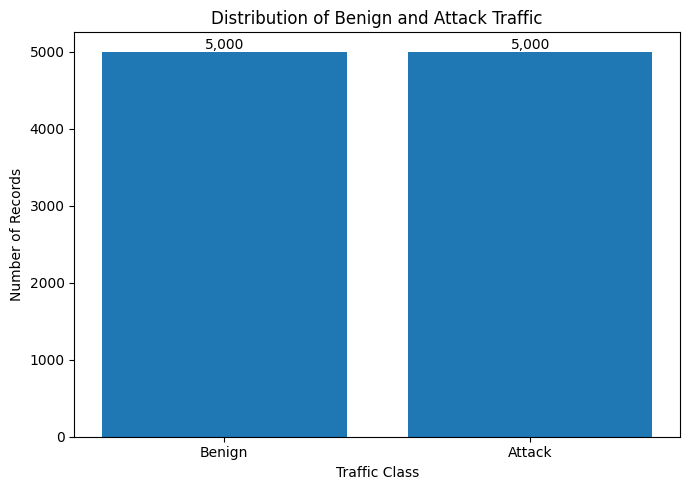

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

class_counts = df["attack"].map({
    0: "Benign",
    1: "Attack"
}).value_counts().reindex(["Benign", "Attack"])

plt.figure(figsize=(7, 5))
bars = plt.bar(class_counts.index, class_counts.values)

plt.title("Distribution of Benign and Attack Traffic")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("dataset_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()



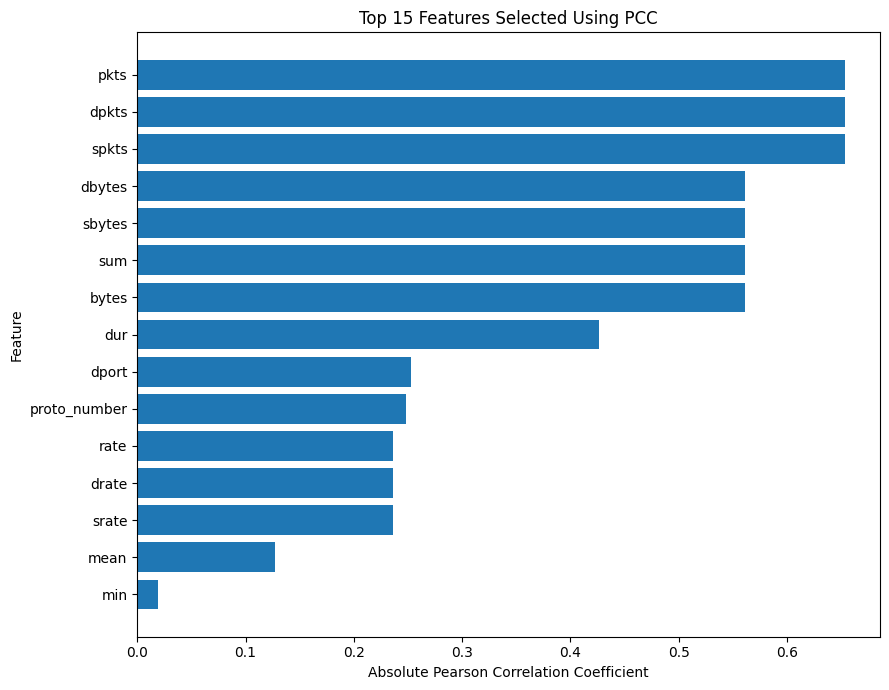

In [ ]:

# Top 15 features selected using PCC

top_pcc = pcc_scores.head(15).sort_values()

plt.figure(figsize=(9, 7))
plt.barh(top_pcc.index, top_pcc.values)

plt.title("Top 15 Features Selected Using PCC")
plt.xlabel("Absolute Pearson Correlation Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("pcc_feature_selection.png", dpi=300, bbox_inches="tight")
plt.show()


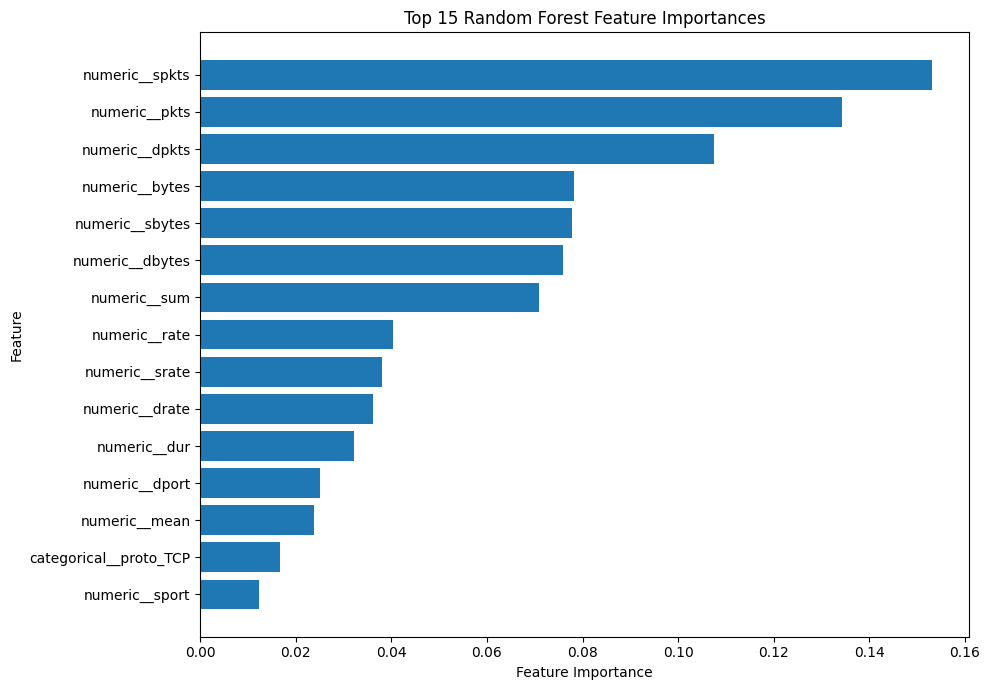

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

importances = rf_model.feature_importances_

# Use transformed feature names if available; otherwise use generic names.
feature_names = None

try:
    feature_names = preprocessor.get_feature_names_out()
except (NameError, AttributeError, ValueError):
    pass

if feature_names is None or len(feature_names) != len(importances):
    feature_names = [
        f"Feature {i + 1}" for i in range(len(importances))
    ]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).head(15)

importance_df = importance_df.sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(importance_df["Feature"], importance_df["Importance"])

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("random_forest_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()


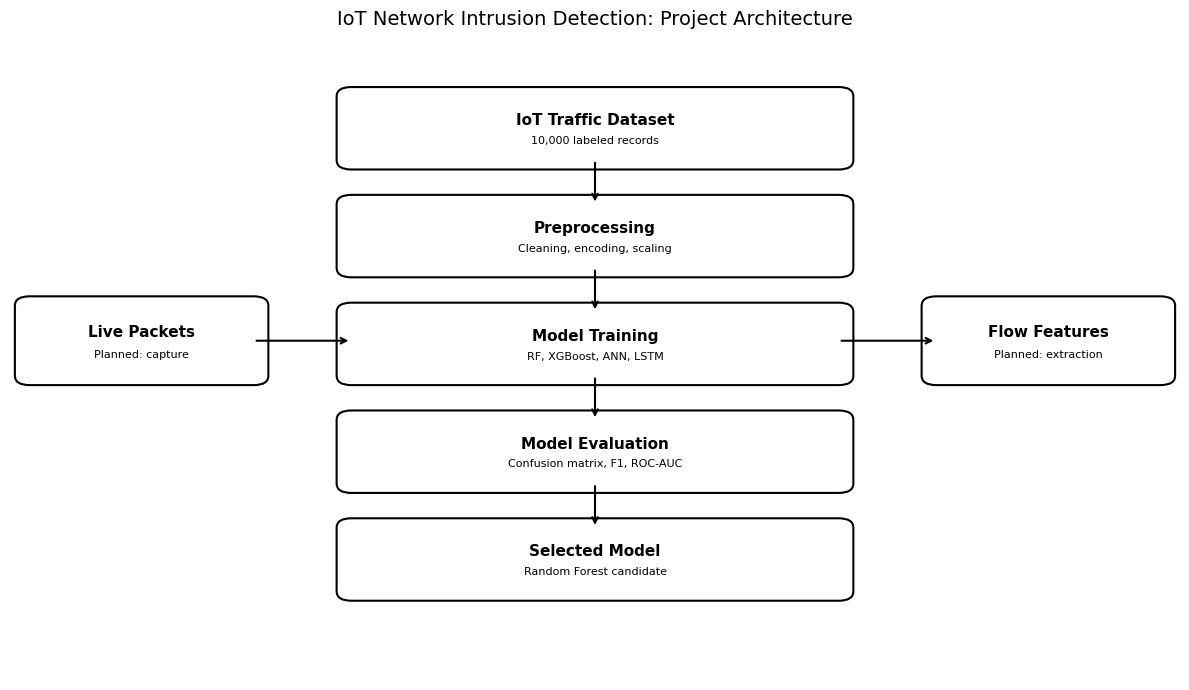

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

def draw_box(x, y, w, h, title, subtitle=""):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="white",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(x + w/2, y + h*0.62, title,
            ha="center", va="center",
            fontsize=11, fontweight="bold")
    if subtitle:
        ax.text(x + w/2, y + h*0.30, subtitle,
                ha="center", va="center", fontsize=8)

def arrow(x1, y1, x2, y2):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

# Main implemented experimental workflow
draw_box(3.5, 8.2, 5, 1, "IoT Traffic Dataset",
         "10,000 labeled records")
draw_box(3.5, 6.5, 5, 1, "Preprocessing",
         "Cleaning, encoding, scaling")
draw_box(3.5, 4.8, 5, 1, "Model Training",
         "RF, XGBoost, ANN, LSTM")
draw_box(3.5, 3.1, 5, 1, "Model Evaluation",
         "Confusion matrix, F1, ROC-AUC")
draw_box(3.5, 1.4, 5, 1, "Selected Model",
         "Random Forest candidate")

arrow(6, 8.2, 6, 7.5)
arrow(6, 6.5, 6, 5.8)
arrow(6, 4.8, 6, 4.1)
arrow(6, 3.1, 6, 2.4)

# Planned extension
draw_box(0.2, 4.8, 2.3, 1.1, "Live Packets",
         "Planned: capture")
draw_box(9.5, 4.8, 2.3, 1.1, "Flow Features",
         "Planned: extraction")

arrow(2.5, 5.35, 3.5, 5.35)
arrow(8.5, 5.35, 9.5, 5.35)

ax.set_title("IoT Network Intrusion Detection: Project Architecture",
             fontsize=14, pad=15)

plt.tight_layout()
plt.savefig("iot_ids_architecture.png", dpi=300, bbox_inches="tight")
plt.show()


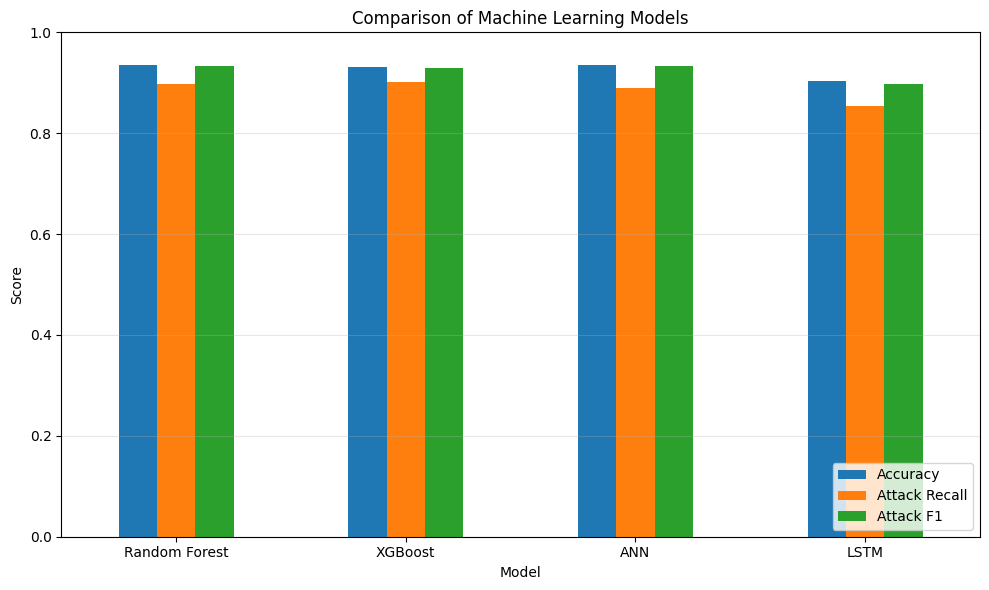

In [ ]:

# Compare Accuracy, Attack Recall and Attack F1

metrics = ["Accuracy", "Attack Recall", "Attack F1"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_performance_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


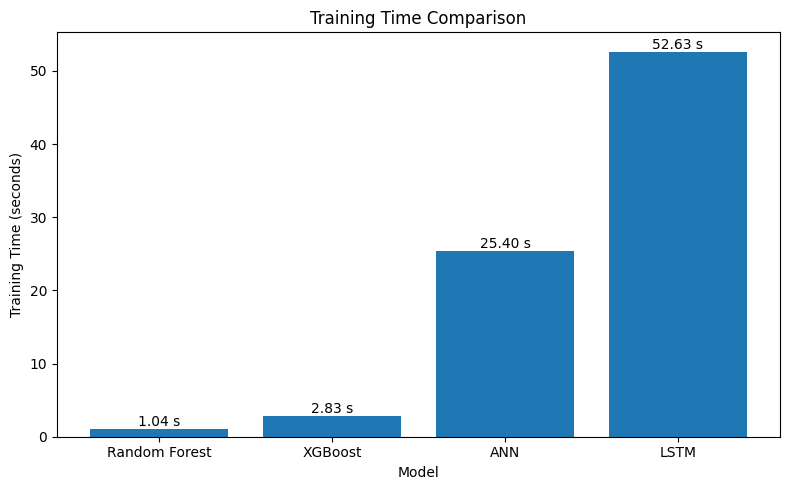

In [ ]:

training_times = {
    "Random Forest": 1.04,
    "XGBoost": 2.83,
    "ANN": 25.40,
    "LSTM": 52.63
}

plt.figure(figsize=(8, 5))
bars = plt.bar(
    training_times.keys(),
    training_times.values()
)

plt.title("Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=0)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.2f} s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("training_time_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
from google.colab import files

files.download("iot_ids_architecture.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("training_time_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("model_performance_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("random_forest_feature_importance.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("pcc_feature_selection.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("dataset_class_distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>